# Underfitting y Overfitting
**Sobreajuste y subajuste**

## Experimentando con diferentes modelos

Ahora que tenemos una forma confiable de medir la precisión del modelo, podemos experimentar con modelos alternativos y ver cuál da las mejores predicciones. Pero, ¿qué alternativas tenemos para los modelos?

Podemos ver en la [documentación](http://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html) de scikit-learn que el modelo de árbol de decisión tiene muchas opciones (más de las que querríamos o necesitaríamos por mucho tiempo). Las opciones más importantes determinan la profundidad del árbol. Recordemos que la profundidad de un árbol es una medida de cuántas divisiones realiza antes de llegar a una predicción. Este es un árbol relativamente poco profundo.


<img src="./img/tree3.png" alt="arbol" width="600" />

---

En la práctica, no es raro que un árbol tenga 10 divisiones entre el nivel superior (todas las casas) y una hoja. A medida que el árbol se profundiza, el conjunto de datos se divide en hojas con menos casas. Si un árbol solo tuviera 1 división, dividiría los datos en 2 grupos. Si cada grupo se divide nuevamente, obtendríamos 4 grupos de casas. Dividiendo cada uno de esos nuevamente, crearíamos 8 grupos. Si seguimos duplicando el número de grupos añadiendo más divisiones en cada nivel, tendríamos 1024 grupos de casas para cuando lleguemos al nivel 10. Eso son 1024 hojas.

Cuando dividimos las casas entre muchas hojas, también tenemos menos casas en cada hoja. Las hojas con muy pocas casas harán predicciones que son bastante cercanas a los valores reales de esas casas, pero pueden hacer predicciones muy poco fiables para nuevos datos (porque cada predicción se basa en solo unas pocas casas).

Este es un fenómeno llamado sobreajuste, donde un modelo se ajusta casi perfectamente a los datos de entrenamiento, pero tiene un rendimiento deficiente en la validación y otros datos nuevos. Por otro lado, si hacemos nuestro árbol muy poco profundo, no divide las casas en grupos muy distintos.

En un extremo, si un árbol divide las casas en solo 2 o 4 grupos, cada grupo todavía tiene una gran variedad de casas. Las predicciones resultantes pueden estar muy lejos para la mayoría de las casas, incluso en los datos de entrenamiento (y también serán malas en la validación por la misma razón).

> El sobreajuste ocurre cuando un modelo se ajusta demasiado bien a los datos de entrenamiento pero falla en generalizar a datos nuevos, mientras que el subajuste ocurre cuando un modelo es demasiado simple para capturar los patrones en los datos de entrenamiento, resultando en un rendimiento deficiente incluso en esos datos.

---

Como nos importa la precisión en los datos nuevos, la cual estimamos a partir de nuestros datos de validación, queremos encontrar el punto óptimo entre el subajuste y el sobreajuste. Visualmente, queremos el punto más bajo de la curva de validación (roja) en la siguiente imagen.


<img src="./img/mae.png" alt="mae" width="500">

Las dos curvas de color en el gráfico representan cómo varía el error absoluto medio (Mean Absolute Error) en función de la profundidad del árbol de decisión para dos conjuntos de datos diferentes: los datos de entrenamiento y los datos de validación.

- Curva azul (Training): Esta curva muestra el error absoluto medio en los datos de entrenamiento a medida que la profundidad del árbol aumenta. A medida que la profundidad del árbol crece, el modelo se ajusta mejor a los datos de entrenamiento, lo que resulta en un error menor. Sin embargo, si el árbol es demasiado profundo, puede llegar a sobreajustarse a los datos de entrenamiento, capturando incluso el ruido y las peculiaridades específicas de esos datos.

- Curva roja (Validation): Esta curva muestra el error absoluto medio en los datos de validación (un conjunto de datos diferente que no se usó para entrenar el modelo). Inicialmente, a medida que la profundidad del árbol aumenta, el error en los datos de validación disminuye porque el modelo está capturando mejor los patrones generales de los datos. Sin embargo, después de un cierto punto (el punto óptimo), seguir aumentando la profundidad del árbol comienza a incrementar el error en los datos de validación. Esto sucede porque el modelo empieza a sobreajustarse a los datos de entrenamiento y pierde la capacidad de generalizar bien para datos nuevos.

---

## Encontremos un mejor modelo

Hay algunas alternativas para controlar la profundidad del árbol, y muchas permiten que algunas rutas a través del árbol tengan mayor profundidad que otras rutas. Pero el argumento max_leaf_nodes proporciona una forma muy sensata de controlar el sobreajuste frente al subajuste. Cuantas más hojas permitamos que el modelo haga, más nos movemos del área de subajuste en el gráfico anterior al área de sobreajuste.

Creemos una función para comparar las puntuaciones de MAE de diferentes valores para max_leaf_nodes:

In [1]:
from sklearn.metrics import mean_absolute_error
from sklearn.tree import DecisionTreeRegressor

def calcular_mae(max_hojas, train_X, val_X, train_y, val_y):
    modelo = DecisionTreeRegressor(max_leaf_nodes=max_hojas, random_state=0)
    modelo.fit(train_X, train_y)
    preds = modelo.predict(val_X)
    mae = mean_absolute_error(val_y, preds)
    return(mae)

Creemos nuestros datasets para usar la función

In [2]:
from sklearn.model_selection import train_test_split
import pandas as pd

# Cargar datos
ruta = './data/melb_data.csv'
melbourne_data = pd.read_csv(ruta) 

# Quitar nulos
melbourne_data_filtrada = melbourne_data.dropna(axis=0)

# Elegir target (crear y)
y = melbourne_data_filtrada.Price

# Elegir features
melbourne_features = ['Rooms', 'Bathroom', 'Landsize', 'BuildingArea', 'YearBuilt', 'Lattitude', 'Longtitude']

# Crear X
X = melbourne_data_filtrada[melbourne_features]

train_X, val_X, train_y, val_y = train_test_split(X, y, random_state = 0)

assert len(train_X) + len(val_X) == len(X)
assert train_X.index.intersection(val_X.index).empty
assert train_X.index.equals(train_y.index) and val_X.index.equals(val_y.index)
print(f"Filas completas: {len(X):,}; entrenamiento: {len(train_X):,}; validación: {len(val_X):,}")

Filas completas: 6,196; entrenamiento: 4,647; validación: 1,549


Ahora llamemos la función que creamos con diferentes valores de `max_leaf_nodes` para que podamos analizar los resultados y decidir cuál es el parámetro óptimo para este modelo con estos datos.

In [3]:
hojas = [5, 50, 500, 600, 700, 800, 1000, 5000]
maes = []
for max_hojas in hojas:
    error = calcular_mae(max_hojas, train_X, val_X, train_y, val_y)
    print(f"Maximo de hojas: {max_hojas:4d} | MAE validación: {error:,.6f}")
    maes.append(error)

Maximo de hojas:    5 | MAE validación: 347,380.338333
Maximo de hojas:   50 | MAE validación: 258,171.212024
Maximo de hojas:  500 | MAE validación: 243,495.963618
Maximo de hojas:  600 | MAE validación: 243,951.094178
Maximo de hojas:  700 | MAE validación: 242,954.685712
Maximo de hojas:  800 | MAE validación: 244,042.742187
Maximo de hojas: 1000 | MAE validación: 247,378.753656
Maximo de hojas: 5000 | MAE validación: 255,575.129116


,Nodos,MAE
0,5,347380.338333
1,50,258171.212024
2,500,243495.963618
3,600,243951.094178
4,700,242954.685712
5,800,244042.742187
6,1000,247378.753656
7,5000,255575.129116


Menor MAE entre candidatos: 242,954.685712; max_leaf_nodes=700


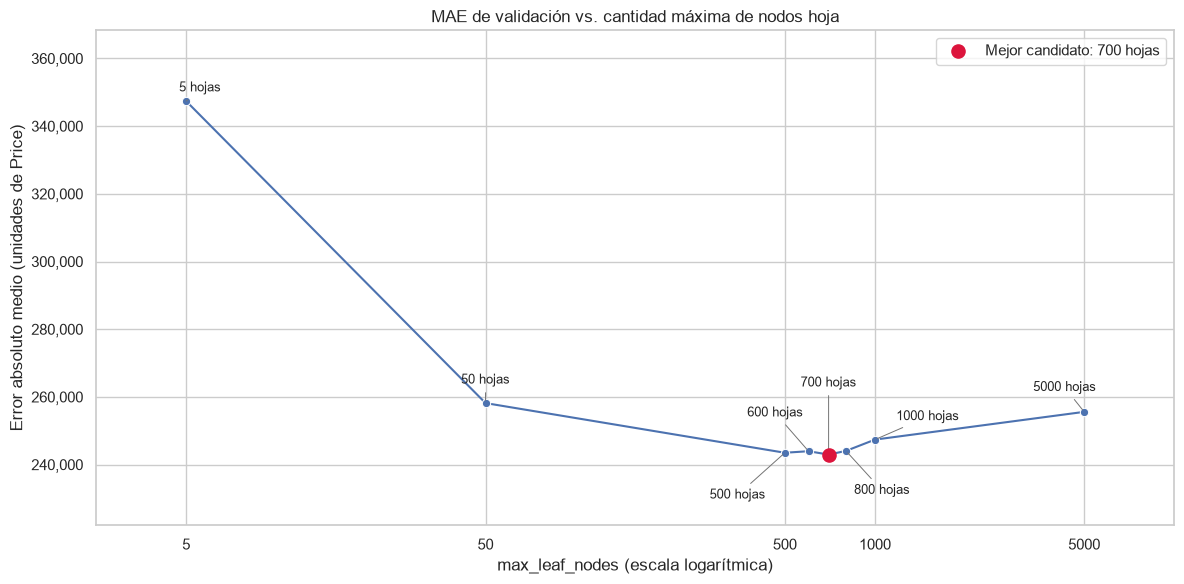

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter, StrMethodFormatter

# Tabla construida con los ocho errores de validación realmente calculados.
data = pd.DataFrame({'MAE': maes, 'Nodos': hojas})
display(data[['Nodos', 'MAE']].round(6))
mejor = data.loc[data['MAE'].idxmin()]
mejores_hojas = int(mejor['Nodos'])
print(f"Menor MAE entre candidatos: {mejor['MAE']:,.6f}; max_leaf_nodes={mejores_hojas}")

sns.set_theme(style='whitegrid')
fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(data=data, x='Nodos', y='MAE', marker='o', estimator=None, ax=ax)
ax.scatter(mejores_hojas, mejor['MAE'], color='crimson', s=90, zorder=5,
           label=f'Mejor candidato: {mejores_hojas} hojas')
ax.set_xscale('log')
ax.set_xticks([5, 50, 500, 1000, 5000])
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
ax.set_title('MAE de validación vs. cantidad máxima de nodos hoja')
ax.set_xlabel('max_leaf_nodes (escala logarítmica)')
ax.set_ylabel('Error absoluto medio (unidades de Price)')

# Desplazamientos distintos evitan superponer las etiquetas cercanas a 500-1000.
desplazamientos = [(10, 7), (0, 14), (-34, -33), (-24, 25), (0, 49),
                   (26, -31), (38, 14), (-14, 15)]
for fila, offset in zip(data.itertuples(index=False), desplazamientos):
    ax.annotate(f'{int(fila.Nodos)} hojas', (fila.Nodos, fila.MAE),
                xytext=offset, textcoords='offset points', ha='center', fontsize=9,
                arrowprops={'arrowstyle': '-', 'color': '0.45', 'lw': 0.7})
ax.margins(x=0.10, y=0.20)
ax.legend(loc='upper right')
fig.tight_layout()
# La salida PNG queda guardada dentro de este notebook al guardar su ejecución.
plt.show()

**Conclusión:** Entre los ocho valores probados, **700 hojas ofrecen el menor MAE de validación: 242,954.685712**. Este resultado corresponde a los datos, las siete características, los parámetros y la partición utilizados (`dropna(axis=0)`, `DecisionTreeRegressor` y `random_state=0` en la división y el estimador). No representa necesariamente el valor óptimo para otro problema, otra partición o candidatos no evaluados.

### Respuestas y comprobación con los resultados ejecutados

1. **¿Cuál es el mejor valor entre los probados?** `data['MAE'].idxmin()` selecciona **700 hojas**, con MAE de validación **242,954.685712**. Con 500 hojas el MAE fue 243,495.963618, mayor que el de 700 hojas; por eso se seleccionan 700. Es el mejor **de estos ocho candidatos**, para estas características y esta partición; no se demuestra un óptimo universal. `max_leaf_nodes` limita el número de hojas, no el número total de nodos ni directamente la profundidad.

2. **¿Cómo se relaciona la complejidad con la generalización?** Con 5 hojas el MAE de validación fue **347,380.338333**: un árbol tan simple agrupa viviendas distintas y presenta subajuste. Al permitir 700 hojas el error baja. Con 5000 hojas sube a **255,575.129116**; esta pérdida de rendimiento frente al mejor candidato es compatible con sobreajuste. Una mayor complejidad puede aprender peculiaridades de entrenamiento que no generalizan. La curva no tiene por qué ser estrictamente monótona entre candidatos.

3. **¿Qué se compara y cómo se selecciona?** Cada llamada a `calcular_mae` ajusta un árbol con `train_X` y `train_y`, predice en `val_X` y compara exclusivamente con `val_y`. Los ocho errores se muestran con decimales y alimentan la tabla y la figura; el eje horizontal es logarítmico para distinguir sus escalas. Ninguna llamada ajusta el árbol con validación. Esta partición se usa para elegir el hiperparámetro, por lo que su mínimo **no equivale a una prueba final independiente**; una evaluación final requeriría otros datos reservados o un protocolo adecuado de validación cruzada.

Se conservaron los enunciados, las respuestas y las imágenes originales; la conclusión se actualizó con el mínimo calculado. Los ocho valores y la conclusión del README coinciden con la tabla ejecutada. Este notebook carga sus datos, importa sus dependencias y se ejecuta desde un kernel nuevo, sin variables del notebook 1.
